# 01 · Dataset de buracos

**Fonte:** *Pothole Dataset* público (Roboflow Public, originalmente publicado no Kaggle por Atikur Rahman Chitholian),
665 imagens com a classe única `pothole`, licença **ODbL v1.0**. Exportado em formato **YOLOv8** e descompactado em
`dados/brutos/roboflow_pothole/` (ver `dados/README.md`).

O `montar_dataset.py` junta as divisões do zip, unifica a classe em `buraco`, descarta rótulos malformados e redivide
70/20/10 (treino/validação/teste) com semente fixa 42.

**Limitação conhecida:** o dataset não tem imagens negativas (sem buraco) e tem poucas ruas parecidas com as
brasileiras — isso aparece na análise de erros (notebook 03).

In [1]:
import json, os, sys, random
from pathlib import Path
import matplotlib.pyplot as plt
import cv2
RAIZ = Path("..").resolve()

In [2]:
!{sys.executable} ../scripts/montar_dataset.py --fonte ../dados/brutos/roboflow_pothole:publico --saida ../dados/zelacidade

{
  "fontes": {
    "publico": {
      "pasta": "../dados/brutos/roboflow_pothole",
      "imagens": 665,
      "train": 465,
      "val": 133,
      "test": 67
    }
  },
  "splits": {
    "train": 465,
    "val": 133,
    "test": 67
  },
  "caixas": {
    "train": 1259,
    "val": 304,
    "test": 177
  },
  "negativas": {
    "train": 0,
    "val": 0,
    "test": 0
  }
}
Configuração do dataset: ..\dados\zelacidade\zelacidade.yaml


In [3]:
est = json.load(open(RAIZ / "dados/zelacidade/estatisticas.json", encoding="utf-8"))
est

{'fontes': {'publico': {'pasta': '../dados/brutos/roboflow_pothole',
   'imagens': 665,
   'train': 465,
   'val': 133,
   'test': 67}},
 'splits': {'train': 465, 'val': 133, 'test': 67},
 'caixas': {'train': 1259, 'val': 304, 'test': 177},
 'negativas': {'train': 0, 'val': 0, 'test': 0}}

## Tamanho e posição das caixas

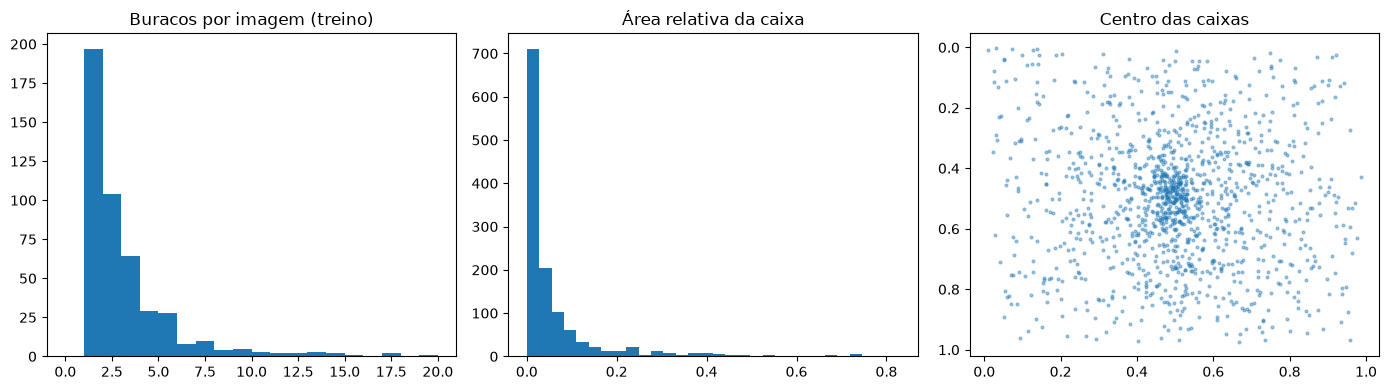

In [4]:
import numpy as np
ws, hs, cxs, cys, por_img = [], [], [], [], []
for txt in (RAIZ / "dados/zelacidade/labels/train").glob("*.txt"):
    linhas = txt.read_text().splitlines()
    por_img.append(len(linhas))
    for l in linhas:
        _, cx, cy, w, h = map(float, l.split()); cxs.append(cx); cys.append(cy); ws.append(w); hs.append(h)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].hist(por_img, bins=range(0, max(por_img) + 2)); ax[0].set_title("Buracos por imagem (treino)")
ax[1].hist(np.array(ws) * np.array(hs), bins=30); ax[1].set_title("Área relativa da caixa")
ax[2].scatter(cxs, cys, s=4, alpha=.4); ax[2].invert_yaxis(); ax[2].set_title("Centro das caixas")
plt.tight_layout(); plt.show()

## Amostras anotadas

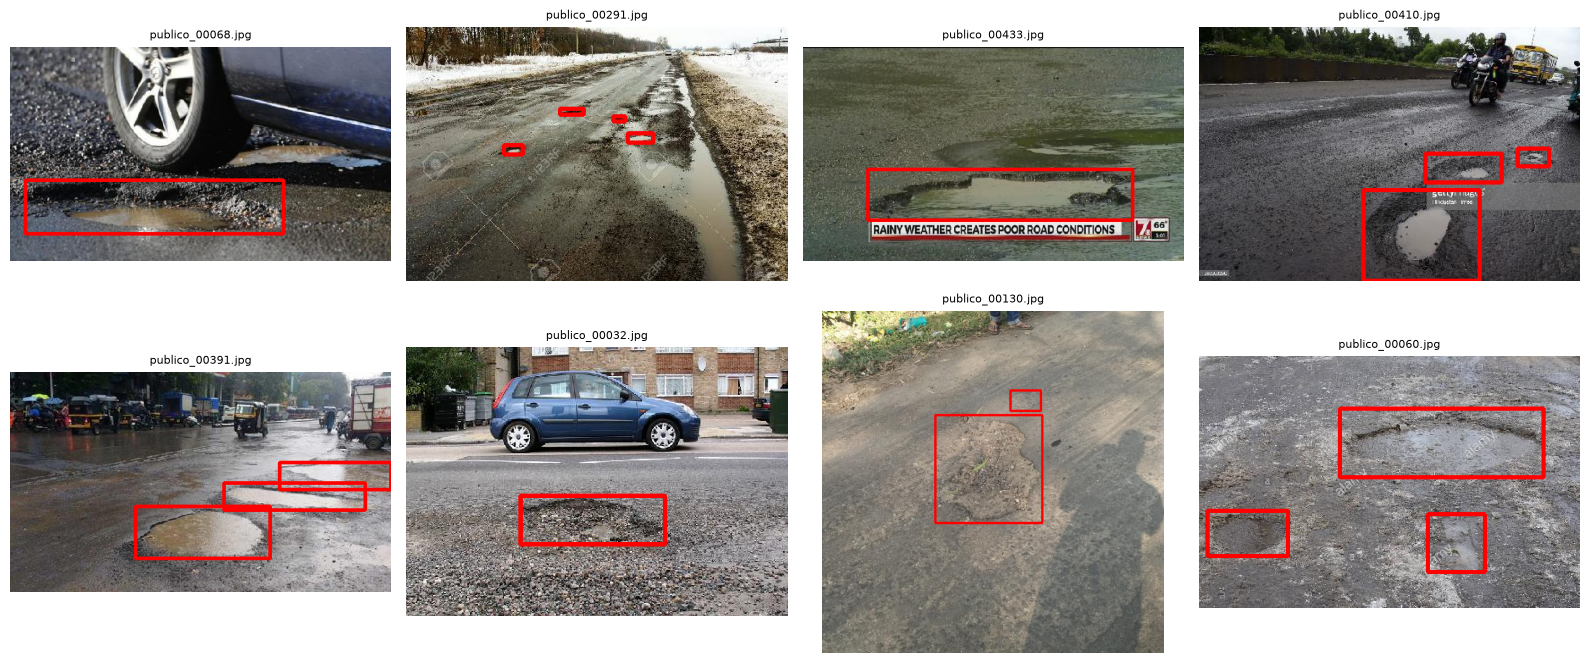

In [5]:
imgs = sorted((RAIZ / "dados/zelacidade/images/train").glob("*"))
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, p in zip(axs.ravel(), random.Random(1).sample(imgs, 8)):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    for l in (RAIZ / "dados/zelacidade/labels/train" / f"{p.stem}.txt").read_text().splitlines():
        _, cx, cy, bw, bh = map(float, l.split())
        cv2.rectangle(im, (int((cx-bw/2)*w), int((cy-bh/2)*h)), (int((cx+bw/2)*w), int((cy+bh/2)*h)), (255, 0, 0), 3)
    ax.imshow(im); ax.set_title(p.name, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()